# Binary Classification of Spike Train Intensity Using a Spiking Neuron

This notebook presents a numerical experiment in which a SNN is trained to perform binary classification of input spike trains. The classification target is whether the firing rate $\lambda$ of the input spike train exceeds a fixed threshold $\Lambda$.

Training relies on a novel approach: instead of standard surrogate-gradient backpropagation through spike emission, the loss is computed analytically via the **first-passage probability** of the neuron's membrane potential, derived using the **Wiener–Hopf factorization** method.

### Installation

The custom spiking neuron model **ExpNeuron** is hosted in a dedicated repository. The repository is cloned directly from GitHub before importing the module.

### Imports

Standard scientific computing libraries (`numpy`, `torch`) are imported alongside `snntorch` for surrogate gradient support and the custom `ExpNeuron` module from the cloned repository.

In [2]:
import torch
import torch.nn as nn
import snntorch as snn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import time
from SNN import ExpNeuron

# 0. Theory and Definitions


### Binary classification task

Let $\Lambda \in (0, 1)$ be a fixed intensity threshold. For each input sample with firing rate $\lambda$, the binary label is defined as

$$
y = \begin{cases} 1, & \lambda \geq \Lambda, \\ 0, & \lambda < \Lambda  \end{cases}
$$

The input to the neuron is a Poisson spike train of length $T$: at each discrete time step $t \in \{1, \ldots, T\}$ a spike $s[t] \in \{0, 1\}$ is drawn independently with $\mathbb{P}(s[t]=1) = \lambda$.

# Theory

## 1.  Model and reduction to the mirror process
**Suggested model**

The original membrane potential process is defined as:
$$
U(t) = U_{0} \exp(-\beta t + \sum_{i=1}^{M}w_i I_i(t))
$$
Where $I_i(t)$ is a Poisson process with intensity $\lambda_{i}$. Reset mechanism:
$$
U(t) > U_{th}, \quad U(t) = U_{0},
$$
where
$U_{th}$ is neuron threshold.


**Log‑potential**  
The log-process $\log(U(t)/U_0)$ is defined as
$$
X_t = -\beta t + \sum_{i=1}^{M} w_i I_i(t),\qquad \beta>0,\; w_i>0,
$$
$I_i(t)\sim\text{Poisson}(\lambda_i t)$ independent.  
$X_t$ is **spectrally positive** (negative drift, positive jumps).  

**First passage to an upper barrier**  

$$
\tau_x^+ = \inf\{t\ge 0 : X_t \ge x\},\qquad x = \ln\frac{U_{\text{th}}}{U_0}>0.
$$

Define the **mirror process**  

$$
Y_t = -X_t = \beta t - \sum_{i=1}^{M} w_i I_i(t).
$$

$Y_t$ is **spectrally negative** (positive drift, negative jumps).  
The event of interest becomes  

$$
\{\tau_x^+ \le t\} = \{\inf_{0\le s\le t} Y_s \le -x\}.
$$

---

## 2.  Laplace transform of $\tau_x^+$

Let $\psi_Y(\theta) = \log\mathbb{E}[e^{\theta Y_1}]$ be the Laplace exponent of $Y$:

$$
\psi_Y(\theta) = \beta\theta + \sum_{i=1}^{M} \lambda_i\bigl(e^{-\theta w_i} - 1\bigr),\qquad \theta\in\mathbb{R}.
$$

For $q>0$, the equation $\psi_Y(\theta)=q$ has a unique positive solution $\Phi(q)$ (used for the supremum factor).  
The Laplace–Stieltjes transform of $\tau_x^+$ is  

$$
L(q) := \mathbb{E}\bigl[e^{-q\tau_x^+}\bigr]
      = \mathbb{P}\bigl(\underline{Y}_{T_q} \le -x\bigr),
$$

where $T_q\sim\text{Exp}(q)$ independent. This probability is given exactly by the absolutely convergent Fourier integral (Gil–Pelaez with atom subtraction):

$$
\boxed{
L(q) = \frac{1-p_0}{2}
      - \frac{1}{\pi}\int_0^\infty
        \operatorname{Im}\!\Bigl[ e^{i\xi x}\bigl(\phi_-(\xi)-p_0\bigr) \Bigr]
        \frac{d\xi}{\xi}
},
$$

where  

- $p_0 = \dfrac{q}{\beta\,\Phi(q)}$ (atom of $\underline{Y}_{T_q}$ at zero),
- $\phi_-(\xi) = \dfrac{q}{\Phi(q)}\,
   \dfrac{\Phi(q)-i\xi}{q+\Psi_Y(\xi)}$ (characteristic function of $\underline{Y}_{T_q}$),
- $\Psi_Y(\xi) = -i\beta\xi + \sum_{i=1}^{M}\lambda_i\bigl(1-e^{-i\xi w_i}\bigr)$ (characteristic exponent of $Y$).

The integrand decays as $O(1/\xi^2)$; the integral can be discretised on a log‑spaced grid with trapezoidal weights.

---

## 3.  Gaver–Stehfest inversion for the fixed‑time probability

The cumulative distribution function $F(T) = \mathbb{P}(\tau_x^+ \le T)$ satisfies  

$$
\widehat{F}(q) = \frac{L(q)}{q} = \int_0^\infty e^{-qT} F(T)\, dT.
$$

We invert $\widehat{F}(q)$ at $T$ using the Gaver–Stehfest formula of even order $N=14$.

**Gaver–Stehfest coefficients** for $N=14$:

$$
\omega_k^{(14)} = \frac{(-1)^{k+7}}{7!}
   \sum_{j=\lfloor (k+1)/2\rfloor}^{\min(k,7)}
   j^{8}\binom{2j}{j}\,
   \frac{1}{(7-j)!\,j!\,(j-1)!\,(k-j)!\,(2j-k)!},\quad k=1,\dots,14.
$$


**Inversion formula**

$$
\boxed{\;
F(T) \;\approx\; \sum_{k=1}^{14} \frac{\omega_k^{(14)}}{k}\,
         L\!\left(\frac{k\ln 2}{T}\right)\; }.
$$

# Precomputed $\frac{\omega_k^{(14)}}{k}$ coefficients for Gaver-Stehfest N=14 (float64 precision)
COEFFS_CDK_N14 = np.array([
     0.002777777777777778, -3.201388888888889,  308.01666666666665,
    -8649.481944444445,  108064.22222222222,  -733057.7277777778,
     3012513.111111111,  -7993114.130555555,  14177508.838888889,
   -17013718.808333334,  13666133.366666666,  -7049346.791666667,
     2113760.3666666665,   -280396.7833333333
], dtype=np.float64)
---

## 4.  Complete algorithm (step by step)

**Inputs**  
$\beta > 0$, $w_1,\dots,w_M > 0$, $\lambda_1,\dots,\lambda_M > 0$,  
$U_0 < U_{\text{th}}$, time horizon $T > 0$.

**Step 0.**  Set $x = \ln(U_{\text{th}}/U_0)$.  
Precompute the Gaver–Stehfest coefficients $\omega_k^{(14)}$ (same for all evaluations).  
Set up the log‑spaced Fourier quadrature grid $\{\xi_j\}_{j=1}^{N_\xi}$ and trapezoidal weights $d\xi_j$ (e.g. $N_\xi = 256$, $\xi_{\min}=0$, $\xi_{\max}=100/x$).

**For each $k = 1,\dots,14$:**

1. $q_k \gets \dfrac{k\ln 2}{T}$.

2. **Find the positive root $\Phi(q_k)$** of $\psi_Y(\theta)=q_k$:  
   $$
   \beta\theta + \sum_{i=1}^{M}\lambda_i\bigl(e^{-\theta w_i}-1\bigr) = q_k.
   $$
   Use Brent’s method on $(0,\,(q_k+\sum\lambda_i)/\beta]$.
   Derivative if using Newton: $\psi_Y'(\theta) = \beta - \sum \lambda_i w_i e^{-\theta w_i}$.

3. **Compute the atom** $p_0 = q_k/(\beta\,\Phi(q_k))$.

4. **Build the characteristic exponent** $\Psi_Y(\xi) = -i\beta\xi + \sum_{i=1}^{M}\lambda_i(1-e^{-i\xi w_i})$ on the $\xi$ grid.

5. **Construct the Wiener–Hopf factor**  
   $$
   \phi_-(\xi) = \frac{q_k}{\Phi(q_k)}\,
                \frac{\Phi(q_k)-i\xi}{q_k + \Psi_Y(\xi)}.
   $$

6. **Assemble the integrand**  
   $$
   I(\xi) = \operatorname{Im}\!\Bigl[ e^{i\xi x}\bigl(\phi_-(\xi)-p_0\bigr) \Bigr] \frac{1}{\xi}.
   $$

7. **Numerical integration** (trapezoidal rule):  
   $$
   \text{Int} = \sum_{j=1}^{N_\xi} I(\xi_j)\, d\xi_j.
   $$

8. **Single‑step transform**  
   $$
   L_k = \frac{1-p_0}{2} - \frac{\text{Int}}{\pi}.
   $$
   Clamp to $[0,1]$ if necessary.

**Assemble the Gaver–Stehfest sum**  

$$
F(T) = \sum_{k=1}^{14} \frac{\omega_k^{(14)}}{k}\, L_k.
$$

Clamp final probability to $[0,1]$.

**Output:** $P(\tau_x^+ \le T) = F(T)$.

---

## 5.  Remarks on the behavior of $\widetilde{\phi}_-(\xi)$ for large and small $\xi$

### 5.1  Decay as $|\xi|\to\infty$

For large $\xi$, $\Psi(\xi)\sim -i\beta\xi$ (the Poisson term is bounded). Hence

$$
q+\Psi(\xi)\sim -i\beta\xi,\qquad
\Phi(q)-i\xi\sim -i\xi,
$$

and

$$
\phi_-(\xi)\sim \frac{q}{\Phi(q)}\frac{-i\xi}{-i\beta\xi}
         = \frac{q}{\beta\Phi(q)}=p_0 .
$$

The next term in the asymptotic expansion comes from the bounded part of $\Psi$. Write

$$
\frac{1}{q+\Psi(\xi)}=\frac{1}{-i\beta\xi\Bigl(1+\frac{q+O(1)}{-i\beta\xi}\Bigr)}
                     =-\frac1{i\beta\xi}\Bigl(1-\frac{q+O(1)}{i\beta\xi}+\cdots\Bigr).
$$

When inserted into $\phi_-$, the constant term $p_0$ cancels, and the remaining $\widetilde{\phi}_-(\xi)$ decays as $O(1/\xi^2)$.  
Consequently, $\displaystyle\frac{\operatorname{Im}\bigl(e^{i\xi x}\widetilde{\phi}_-(\xi)\bigr)}{\xi}=O(1/\xi^3)$, guaranteeing absolute convergence of the integral in (4).

### 5.2  Behavior near $\xi=0$ – removal of the apparent singularity

The integrand in (4) has a factor $1/\xi$, so we must check the limit $\xi\to0$.  
The characteristic function is analytic and obeys $\phi_-(0)=1$.  Expanding around $\xi=0$,

$$
\phi_-(\xi)=1+i\mathbb{E}[\underline{Y}_{T_q}]\xi+O(\xi^2).
$$

Hence

$$
\widetilde{\phi}_-(\xi)=\phi_-(\xi)-p_0 = (1-p_0)+i\mu\xi+O(\xi^2),\qquad
\mu=\mathbb{E}[\underline{Y}_{T_q}]<0 .
$$

Also $e^{i\xi x}=1+i x\xi+O(\xi^2)$.  Therefore

$$
e^{i\xi x}\widetilde{\phi}_-(\xi)
   =(1-p_0)+i\bigl(\mu + x(1-p_0)\bigr)\xi+O(\xi^2).
$$

Taking the imaginary part,

$$
\operatorname{Im}\bigl(e^{i\xi x}\widetilde{\phi}_-(\xi)\bigr)
   =\bigl(\mu + x(1-p_0)\bigr)\xi+O(\xi^3),\qquad \xi\to0.
$$

Dividing by $\xi$,

$$
\frac{\operatorname{Im}\bigl(e^{i\xi x}\widetilde{\phi}_-(\xi)\bigr)}{\xi}
   \xrightarrow{\;\xi\to0\;}\;
   \mu + x(1-p_0),
$$

a **finite limit**.  The apparent singularity at $\xi=0$ is removable; the integrand is continuous (in fact smooth) on $[0,\infty)$.  No special treatment is needed when numerically integrating with a small but positive lower limit.


### Model and utility functions

This block defines all model components and numerical routines used in the experiment.

`PopulationEncoder` transforms a scalar input intensity $\lambda$ into a vector of $N$ intensities $[\lambda_1, \ldots, \lambda_N]$ via Gaussian tuning curves. `PopulationNet` wraps `ExpNeuron` into a population of $N$ neurons performing a sequential forward pass over $T$ time steps, returning the full spike train of shape $(N, T)$. The function `generate_data` generates a synthetic dataset of Poisson firing rates $\lambda$ drawn uniformly from $[\lambda_{\min}, \lambda_{\max}]$ with binary labels defined by threshold $\Lambda$ and returns dataloaders for training and testing.

The remaining functions implement the Wiener–Hopf–based first-passage computation: `psi_Y_complex` evaluates the characteristic exponent $\psi(\xi)$; and `crossing_barrier_prob` assembles all of the above into the final first-passage probability estimate.

The function `target_pattern` computes the Gaussian target firing probability vector for a given class center. The function `train` optimizes weights $\{w_i\}$ via the probabilistic approach using `crossing_barrier_prob` and MSE loss. The function `decode_winner` performs maximum firing rate of the population spike vector. The function `evaluate` runs inference on the real `PopulationNet`, searches for the optimal `lambda_barrier` parameter, and returns the best classification accuracy.

### Population coding

Let $N$ be the number of neurons in the population. Each neuron $i$ has a preferred stimulus $\mu_i$, placed uniformly over the input range $[\lambda_{\min}, \lambda_{\max}]$:

$$
\mu_i = c_i, \quad i = 0, \ldots, N-1
$$

We can choose $\sigma$ value by:
$$
\sigma \approx \frac{\lambda_{\max} - \lambda_{\min}}{N - 1}
$$

It should be noted that $\sigma$ is a parameter that can be determined empirically. In this experiment, $\sigma$ and $\delta$ were selected such that the tuning curves provide sufficient coverage across the full input range $[\lambda_{\min}, \lambda_{\max}]$.  
The input intensity for neuron $i$ given stimulus $\lambda$ is defined via a Gaussian tuning curve:

$$
\lambda_i(\lambda) = \lambda_{\text{scale}} \cdot \exp\left(-\frac{(\lambda - \mu_i)^2}{2\sigma^2}\right)
$$

Each neuron $i$ fires with probability $P_i = P(\tau^+ \leq T \mid \lambda_i, w_i)$ computed via the Wiener–Hopf method described above.

**Target patterns.** For binary classification with threshold $\Lambda$, define class centers:

<!-- $$
c_0 = \frac{\lambda_{\min} + \Lambda}{2}, \qquad c_1 = \frac{\Lambda + \lambda_{\max}}{2}
$$ -->
$$
c_0 = \Lambda - \delta, \qquad c_1 = \Lambda + \delta, \qquad \delta =0.21
$$


The target firing rate for neuron $i$ given class $y$ is:

$$
y_i^{target} = \exp\left(-\frac{(c_i - c_y)^2}{2\sigma^2}\right) =
\begin{cases}
1, & i = y \\
\exp\left(-\frac{(c_0 - c_1)^2}{2\sigma^2}\right), & i \neq y
\end{cases}
$$
This target is used in population network based on LIF model. For training population network with the same parameters for proposed neuron the target firing probability $y_{i,k}^{target}$ for proposed neuron $i$ for the $k$ class is given by $y_{0, 0}^{target} = 1, y_{0, 1}^{target} = 0, y_{1, 0}^{target} = 0, y_{1, 1}^{target} = 1$.

where $\lambda_i(c_y) = \lambda_{\text{scale}} \cdot \exp\left(-\dfrac{(c_y - \mu_i)^2}{2\sigma^2}\right)$
is the encoder output for neuron $i$ given prototype $c_y$. The threshold
$\lambda_{\text{thr}}$ controls which neurons are considered active for a given class.
**Training.** Weights $\{w_i\}$ are optimized by minimizing the MSE between predicted and target firing probabilities:

$$
\mathcal{L} = \frac{1}{N} \sum_{i=1}^{N} \left(P_i(\lambda) - y_i^{\text{target}}\right)^2
$$

**Decoding.** At inference, the real network generates binary spike vectors $s_i \in \{0, 1\}$. The predicted class is selected via spike-presence decoding (winner-take-all with a time-to-first-spike tie-break; a sample where neither neuron fires is an error):

$$
\hat{y} = \text{winner-take-all over presence, tie-break by first spike time}
$$

where $P_i(c)$ denotes the firing probability of neuron $i$ evaluated at class center $c_y$.

`PopulationEncoder` transforms input spike-train intensity $\lambda$ to intensity array using the following formula:
$$
\lambda _i(x) = \lambda _{scale} \cdot \exp \left( -\frac{(x - \mu _{i})^2}{2\sigma ^ 2} \right)
$$
It means that when input spike-train intensity $\lambda$ matches neuron preferred stimulus $\mu_i$ the value of encoded intensities $\lambda_i = 1$ and when input intensity is different $\lambda_i$ tends to zero  

In [3]:
class PopulationEncoder(nn.Module):
	"""
	scalar stimulus x to intensity vector [lambda_1, ..., lambda_N].
	λ_i(x) = λ_scale * exp(-(x - mu_i)^2 / 2sigma^2)
	"""
	def __init__(self, n_neurons, lambda_min, lambda_max, sigma, lambda_scale, mu=None):
		super().__init__()
		if mu is None:
			mu = torch.linspace(lambda_min, lambda_max, n_neurons, dtype=torch.float64)
		else:
			mu = torch.tensor(mu, dtype=torch.float64)

		self.register_buffer('mu', mu)
		self.sigma = sigma
		self.lambda_scale = lambda_scale

	def forward(self, x):
		if x.dim() == 0:
			x = x.unsqueeze(0)
		diff = x.unsqueeze(-1) - self.mu.unsqueeze(0)
		return self.lambda_scale * torch.exp(-diff**2 / (2 * self.sigma**2))

Numerical implementation of the Wiener–Hopf method.
The following functions implement the analytical machinery described in the Theory section above. `make_fourier_grid` builds the log-spaced quadrature grid for the Gil–Pelaez integral. `find_phi_newton` solves $\psi_Y(\theta) = q$ for the Wiener–Hopf root $\Phi(q)$. `psi_Y_complex` evaluates the characteristic exponent on the frequency grid. `laplace_transform` assembles the full Gil–Pelaez inversion for a single Laplace arqument $q$. `crossing_barrier_prob` combines all of the above with the Gaver–Stehfest formula to return the final first-passage probability $P(\tau_x^+ \leq T)$.

In [4]:
GS_COEFFS = torch.tensor([
     0.002777777777777778, -3.201388888888889,   308.01666666666665,
    -8649.481944444445,   108064.22222222222,   -733057.7277777778,
     3012513.111111111,   -7993114.130555555,    14177508.838888889,
    -17013718.808333334,   13666133.366666666,   -7049346.791666667,
     2113760.3666666665,    -280396.7833333333], dtype=torch.float64)


def make_fourier_grid(x: float, n_xi: int = 256):
    """
    Build a log-spaced quadrature grid for the Gil-Pelaez integral.
    Returns node positions xi and trapezoidal weights dxi on (0, 100/x].
    """
    xi_min = 1e-6
    xi_max = 100.0 / x
    xi   = torch.logspace(np.log10(xi_min), np.log10(xi_max), n_xi, dtype=torch.float64)
    dlog = torch.log(xi[1]) - torch.log(xi[0])
    dxi  = xi * dlog
    dxi[0]  *= 0.5
    dxi[-1] *= 0.5
    return xi, dxi

def find_phi_newton(q: float,
                    beta: float,
                    ws: torch.Tensor,
                    lambdas: torch.Tensor,
                    n_iter: int = 8):
    """
    Solve psi_Y(theta) = q for the unique positive root Phi(q) via Newton's method.
    The number of iterations n_iter has a large impact on computational speed.
    """
    q_t = torch.tensor(q, dtype=torch.float64)

    # initial theta estimate, detached from the computation graph
    with torch.no_grad():
        theta = (q_t + lambdas.sum()) / beta

    # Newton iteration
    for _ in range(n_iter):
        exp_wt   = torch.exp(-theta * ws)
        psi      = beta * theta + (lambdas * (exp_wt - 1.0)).sum()
        dpsi     = beta          - (lambdas * ws * exp_wt).sum()
        theta    = theta - (psi - q_t) / dpsi
    # scalar tensor with grad_fn
    return theta


def psi_Y_complex(xi: torch.Tensor,
                    beta: float,
                    w: torch.Tensor,
                    lambd: torch.Tensor):
    """
    Evaluate the characteristic exponent of Y on the real frequency grid:
    Psi_Y(xi) = -i*beta*xi + sum_i lambda_i * (1 - exp(-i*xi*w_i)).
    """
    xi_c   = xi.to(torch.complex128)
    w_c    = w.to(torch.complex128)
    lam_c  = lambd.to(torch.complex128)
    phase  = torch.outer(xi_c, w_c)
    return -1j * beta * xi_c + (lam_c * (1.0 - torch.exp(-1j * phase))).sum(dim=-1)


def laplace_transform(q: float, x: float, beta: float,
                        ws: torch.Tensor, lambdas: torch.Tensor,
                        xi: torch.Tensor, dxi: torch.Tensor):
    """
    Compute L(q) = E[exp(-q * tau_x^+)] via the Gil-Pelaez inversion
    of the Wiener-Hopf factor phi_minus on the precomputed quadrature grid.
    """
    q_t = torch.tensor(q, dtype=torch.float64)

    # Step 2: find positive root Phi(q) of psi_Y(theta) = q
    phi_q = find_phi_newton(q, beta, ws, lambdas)

    # step 3. Atom
    p0 = q_t / (beta * phi_q)

    # step 4. Psi_Y(xi) complex
    Psi = psi_Y_complex(xi, beta, ws, lambdas)

    # step 5. Wiener-Hopf factor
    xi_c      = xi.to(torch.complex128)
    phi_q_c   = phi_q.to(torch.complex128)
    phi_minus = (q_t / phi_q_c) * (phi_q_c - 1j * xi_c) / (q_t + Psi)

    # step 6. Integrand
    tilde_phi = phi_minus - p0.to(torch.complex128)
    integrand = torch.imag(torch.exp(1j * xi_c * x) * tilde_phi) / xi

    # step 7. Computing integral
    integral = (integrand * dxi).sum()

    # step 8.  Single-step transformation
    L = (1.0 - p0) / 2.0 - integral / np.pi
    return L.clamp(0.0, 1.0)


def crossing_barrier_prob(U0: float,
							U_th: float,
							T: float,
							beta: float,
							lambdas: torch.Tensor,
							ws: torch.Tensor,
							n_xi: int = 512):
    """
    Return P(tau_x^+ <= T): the probability that the log-membrane potential
    crosses barrier x = log(U_th / U0) before time T.
    Uses Gaver-Stehfest inversion of order N=14 over 14 Laplace evaluations.
    """
    x       = float(np.log(U_th / U0))
    xi, dxi = make_fourier_grid(x, n_xi=n_xi)
    ln2_T   = np.log(2.0) / T

    L_vals = torch.stack([
        laplace_transform(k * ln2_T, x, beta, ws, lambdas, xi, dxi)
        for k in range(1, 15)])

    return (GS_COEFFS * L_vals).sum().clamp(0.0, 1.0)


In [5]:
def target_pattern(mu, c_y, sigma):
	return torch.exp(-(mu - c_y)**2 / (2 * sigma**2))

Learning using probabilistic approach. In `train` training can be described by following steps:
1. Encode $\lambda _i$ via `PopulationEncoder`
2. Calculate $P_i$ for each neuron
3. Count Loss. MSE has been chosen as loss function.
4. Back propagation

In [6]:
def train(encoder, weights, train_lambda_dataldr,
		  epochs, lr, c_0, c_1, sigma,
		  mem_zero, threshold, steps, beta, lambd):
	"""
	Train synaptic weights via the analytical crossing-probability loss.
	At each step the MSE between crossing_barrier_prob outputs and the
	binary target pattern is minimized with Adam + ReduceLROnPlateau.
	Returns a list of per-epoch mean MSE losses.
	"""
	optimizer = torch.optim.Adam([weights], lr=lr)
	scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
		optimizer, patience=2, factor=0.5)

	mu = encoder.mu
	targets_c0 = torch.tensor([[1., 0.]])
	targets_c1 = torch.tensor([[0., 1.]])


	epoch_losses = []

	for epoch in range(epochs):
		sample_losses = []
		for trn_lambdas, labels in train_lambda_dataldr:
			optimizer.zero_grad()

			# Population input
			lambdas_i = encoder(trn_lambdas).squeeze()
			# Calculating probabilities
			probs = torch.stack([
				crossing_barrier_prob(
					mem_zero, threshold, steps, beta,
					lambdas=lambdas_i[i],
					ws=weights[i:i+1])
				for i in range(len(mu))
			])

			# Target pattern
			target = targets_c1 if labels.item() == 1.0 else targets_c0

			loss = ((probs - target) ** 2).mean()
			loss.backward()
			optimizer.step()

			sample_losses.append(loss.item())

		epoch_loss = float(np.mean(sample_losses))
		epoch_losses.append(epoch_loss)
		scheduler.step(epoch_loss)

		print(f"Epoch {epoch:3d} | loss: {epoch_loss:.6f}")

	return epoch_losses

In [7]:
class PopulationNet(nn.Module):
	"""
	Population of ExpNeuron units driven by weighted Poisson spike trains.
	Weights are applied per-neuron; the forward pass returns the full
	spike and membrane-potential traces of shape (N, T).
	"""
	def __init__(self, weights, encoder, steps,
				 beta, threshold, membrane_zero):
		super().__init__()

		self.encoder = encoder
		self.steps = steps
		self.weights = weights

		self.neuron = ExpNeuron.ExpNeuron(
			beta=beta,
			threshold=threshold,
			membrane_zero=membrane_zero,
			learn_beta=False,
			learn_threshold=False,
			learn_membrane_zero=False)

	def forward(self, spk_input):
		mem = self.neuron.init_neuron()
		spk_outpt = []
		mem_outpt = []
		steps = spk_input.shape[1]

		for step in range(steps):
			spk, mem = self.neuron(spk_input[:, step] * self.weights.detach() )
			spk_outpt.append(spk)
			mem_outpt.append(mem)

		spk_outpt = torch.stack(spk_outpt, dim = 1)
		mem_outpt = torch.stack(mem_outpt, dim = 1)
		return spk_outpt, mem_outpt

Decoding by spike presence. A neuron is considered active if it emits at least one spike within the horizon $T$. The class is chosen by winner-take-all over the presence flags, with a time-to-first-spike tie-break when both neurons fire; if neither neuron fires, the sample is counted as an error.

In [8]:
def decode_presence(spk_TN):
	# spk_TN: (T, N) бинарные спайки одного сэмпла, N=2
	# 1) один спайкнул -> он; 2) оба -> кто раньше (TTFS); 3) никто -> None (ошибка)
	counts = spk_TN.sum(dim=0)
	fired = counts >= 1
	if not bool(fired.any()):
		return None
	T = spk_TN.shape[0]
	has = spk_TN > 0
	first = torch.where(
		has.any(dim=0),
		has.float().argmax(dim=0).to(torch.float64),
		torch.full((spk_TN.shape[1],), float(T), dtype=torch.float64))
	f0, f1 = bool(fired[0]), bool(fired[1])
	if f1 and not f0:
		return 1
	if f0 and not f1:
		return 0
	return 1 if first[1] < first[0] else 0


Testing using SNN based on ExpNeuron model. For each neuron we generate Poisson input with intensity $\lambda_i$ and weight $w_i$. A neuron is active if it fires at least once within $T$; the class is decided by winner-take-all with a time-to-first-spike tie-break, and a sample where neither neuron fires is counted as an error.

In [9]:
def evaluate(encoder, weights, test_dataldr,
			 net, c_0, c_1, num_steps,
			 mem_zero, threshold, beta):
	# тест ExpNeuron: декодирование по наличию спайка (без подбора барьера)
	correct = 0
	for trns, lbls in test_dataldr:
		spk_output, _ = net(trns)
		pred = decode_presence(spk_output.squeeze(0))
		if pred == int(lbls.item()):
			correct += 1
	return correct / len(test_dataldr)


Data generation

In [10]:
def generate_data(test_samples, train_samples, Lambda, lambda_min,
                  lambda_max, encoder, seed=42, eps=5e-3, steps=100):
	"""
	Generate Poisson spike-train datasets for training and testing.
	Firing rates are drawn uniformly from [lambda_min, lambda_max]; labels
	are 1 if lambda >= Lambda (with eps-margin tolerance) and 0 otherwise.
	Returns (train_lambda_dataldr, test_dataldr, train_dataldr).
	"""
	torch.manual_seed(seed)
	np.random.seed(seed)
	train_lambd_arr = torch.ones(train_samples).uniform_(lambda_min, lambda_max)
	test_lambd_arr = torch.ones(test_samples).uniform_(lambda_min, lambda_max)

	test_labels = ((abs(test_lambd_arr - Lambda) <= eps ) | (test_lambd_arr > Lambda)).float().unsqueeze(1)
	train_labels = ((abs(train_lambd_arr - Lambda) <= eps ) | (train_lambd_arr > Lambda)).float().unsqueeze(1)

	# creates neuron_n spike_trains
	test_trains = torch.stack([gen_spike_train(encoder(lambd).squeeze(0), steps) for lambd in test_lambd_arr])
	train_trains = torch.stack([gen_spike_train(encoder(lambd).squeeze(0), steps) for lambd in train_lambd_arr])

	train_data = TensorDataset(train_trains, train_labels)
	train_dataldr = DataLoader(dataset=train_data)

	test_data = TensorDataset(test_trains, test_labels)
	test_dataldr = DataLoader(dataset=test_data)

	train_lambda_data = TensorDataset(train_lambd_arr.unsqueeze(1), train_labels)
	train_lambda_dataldr = DataLoader(dataset=train_lambda_data)

	return train_lambda_dataldr, test_dataldr, train_dataldr

def gen_spike_train(lambd, num_steps):
	"""
	Sample a Poisson spike train of length num_steps with rate vector lambd.
	Returns a tensor of shape (num_steps, N) with non-negative integer counts.
	"""
	lambd = torch.as_tensor(lambd)
	return torch.poisson(lambd.unsqueeze(0).expand(num_steps, -1))

# 1. Experiment Parameters

The dataset consists of `samples` training spike trains and `test_samples` test spike trains, each of length `steps` discrete time steps. Every spike train is generated from a Poisson process with rate $\lambda$ drawn uniformly: $\lambda \sim \mathrm{Uniform}(a, b)$.

The classification boundary is set at $\Lambda = 0.55$: samples with $\lambda \geq \Lambda$ receive label $y = 1$, and $y = 0$ otherwise. A separate dataloader passes the raw firing rates $\lambda$ directly to the analytical crossing-probability formula during training, bypassing spike train generation.

The `ExpNeuron` is instantiated with fixed parameters: decay rate $\beta = 0.05$, firing threshold $U_{th} = 1.0$, and resting potential $U_0 = 0.8$. The only trainable parameter is the synaptic weight $w$, initialized to $0.5$.

Optimization is performed with Adam ($\eta = 2 \times 10^{-4}$).

In [81]:
# Population coding parameters
N_NEURONS    = 2
# Defines the preferred stimulus (mu) distribution across neurons
LAMBDA_MIN   = 0.0
LAMBDA_MAX   = 1.0
LAMBDA   = 0.55
SIGMA        = 0.17
# Scales the maximum encoded intensity
LAMBDA_SCALE = 1.0

# Centers of classes
DELTA = 0.21
C_0 = LAMBDA - DELTA
C_1 = LAMBDA + DELTA

# Neuron parameters
BETA_EXP   = 0.01
BETA_LIF   = 0.95
THRESHOLD  = 1.0
MEM_ZERO   = 0.85
STEPS      = 200

# Learning parameters
EPOCHS      = 15
LR          = 5e-4
LR_LIF 		= 5e-3

# Presence indicator value
ALPHA_PRESENCE 	= 1.0
SAMPLES      	= 50
TEST_SAMPLES 	= 200
SEED         	= 42

# 2. Data Generation

`PopulationEncoder` maps each scalar firing rate $\lambda$ to a vector of $N$ population intensities. `generate_data` draws firing rates uniformly from $[\lambda_{\min}, \lambda_{\max}]$, assigns binary labels relative to threshold $\Lambda$, and returns three dataloaders: one with raw $\lambda$ values for analytical training, one with spike trains for evaluation, and one with spike trains for LIF baseline training.

In [82]:
# encoder and weights initialization
encoder = PopulationEncoder(N_NEURONS, LAMBDA_MIN, LAMBDA_MAX, SIGMA, LAMBDA_SCALE, mu = [C_0, C_1])
# Data generation. train dataldr is needed to train LIF population network
train_lambda_dataldr, test_dataldr, train_dataldr = generate_data(TEST_SAMPLES, SAMPLES, LAMBDA,
                                                   LAMBDA_MIN, LAMBDA_MAX, encoder, SEED, steps=STEPS)

# 3. Training

At each training step the input intensity $\lambda$ is passed to `PopulationEncoder`, which returns the vector of population intensities $[\lambda_1, \ldots, \lambda_N]$. Each $\lambda_i$ is then passed to `crossing_barrier_prob`, which returns the analytically computed firing probability $P_i = \mathbb{P}(\tau^+ \leq T \mid \lambda_i, w_i)$ as a differentiable function of $w_i$. The loss is the mean squared error between these probabilities and the Gaussian target pattern of the true class:

$$
\mathcal{L}(\{w_i\}) = \frac{1}{N} \sum_{i=1}^{N} \left(P_i(\lambda) - y_i^{\text{target}}\right)^2
$$
The probability $P_i$ is computed via the Gaver–Stehfest inversion of the Laplace transform $L(q) = \mathbb{E}[e^{-q\tau^+}]$, which depends on $w_i$ through the characteristic exponent $\psi(\xi)$ and the Wiener–Hopf factor $\phi_-(\xi)$. Since all operations — Fourier quadrature, root finding for $\Phi(q)$, and the Gaver–Stehfest sum — are implemented as differentiable PyTorch operations, gradients $\partial \mathcal{L} / \partial w_i$ flow through the entire computation graph via autograd, enabling direct optimisation of $\{w_i\}$ without surrogate gradients.

Learning
Epoch   0 | loss: 0.138209
Epoch   1 | loss: 0.135408
Epoch   2 | loss: 0.132717
Epoch   3 | loss: 0.130024
Epoch   4 | loss: 0.126957
Epoch   5 | loss: 0.122677
Epoch   6 | loss: 0.117102
Epoch   7 | loss: 0.113069
Epoch   8 | loss: 0.111693
Epoch   9 | loss: 0.111300
Epoch  10 | loss: 0.111150
Epoch  11 | loss: 0.111078
Epoch  12 | loss: 0.111254
Epoch  13 | loss: 0.111100
Epoch  14 | loss: 0.111004
ExpNeuron training: 49.1s
Testing

  Testing accuracy: 95.50%


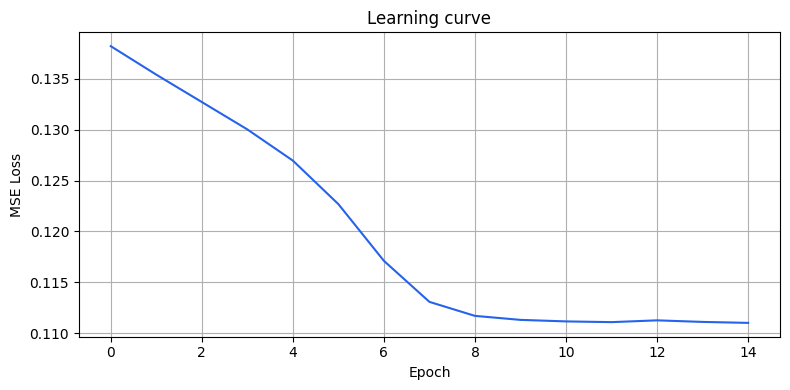

Weights saved to exp_neuron_weights.pt


In [83]:
weights = nn.Parameter(torch.ones(N_NEURONS, dtype=torch.float64) * 0.1)

print("Learning")

t0 = time.time()
losses = train(
	encoder, weights, train_lambda_dataldr,
	EPOCHS, LR, C_0, C_1, SIGMA,
	MEM_ZERO, THRESHOLD, STEPS, BETA_EXP, LAMBDA)
print(f"ExpNeuron training: {time.time()-t0:.1f}s")

print("Testing")
net = PopulationNet(
	weights=weights,
	encoder=encoder,
	steps=STEPS,
	beta=BETA_EXP,
	threshold=THRESHOLD,
	membrane_zero=MEM_ZERO)

accuracy = evaluate(
	encoder, weights, test_dataldr,
	net, C_0, C_1, STEPS,
	MEM_ZERO, THRESHOLD, BETA_EXP)

print(f"\n  Testing accuracy: {accuracy * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.plot(losses, color='#2563EB')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning curve')
plt.tight_layout()
plt.grid()
plt.show()

# Save trained weights for reproducibility
torch.save({
    'weights': weights.data,
    'accuracy': accuracy,
}, 'exp_neuron_weights.pt')
print("Weights saved to exp_neuron_weights.pt")

# 4. Testing
Testing network classification results with input $\Lambda$.

In [84]:
# Load pre-trained weights (skip training if weights file exists)
import os

WEIGHTS_PATH = 'exp_neuron_weights.pt'
if os.path.exists(WEIGHTS_PATH):
    checkpoint = torch.load(WEIGHTS_PATH,  weights_only=False)
    weights = nn.Parameter(checkpoint['weights'])
    net = PopulationNet(
        weights=weights, encoder=encoder, steps=STEPS,
        beta=BETA_EXP, threshold=THRESHOLD, membrane_zero=MEM_ZERO)
    print(f"Loaded weights from {WEIGHTS_PATH}  "
          f"(saved accuracy: {checkpoint['accuracy']*100:.1f}%)")
else:
    print("No saved weights found — run Section 3 first.")


Loaded weights from exp_neuron_weights.pt  (saved accuracy: 95.5%)


In [85]:
# Тест одного значения Lambda
test_lambda = 0.57
spike_train = gen_spike_train(encoder(torch.tensor(test_lambda)).squeeze(0), STEPS)

spk_output, _ = net(spike_train.unsqueeze(0))
pred = decode_presence(spk_output.squeeze(0))

print(f"Net prediction: {pred} (test_lambda: {test_lambda}, LAMBDA: {LAMBDA})")


Net prediction: 0 (test_lambda: 0.57, LAMBDA: 0.55)


# 5. LIF population network

In [86]:
class LIFPopulation(nn.Module):
    """
    Population of Leaky Integrate-and-Fire neurons (snntorch.Leaky)
    with per-neuron weights. Forward returns spike trains of shape (batch, T, N).
    """
    def __init__(self, weights, encoder, steps, beta, threshold):
        super().__init__()
        self.encoder  = encoder
        self.steps    = steps
        self.weights  = weights
        self.neuron   = snn.Leaky(
            beta=beta,
            threshold=threshold,
            learn_beta=False,
            learn_threshold=False)

    def forward(self, spk_input):
        mem = self.neuron.init_leaky()
        spk_output = []
        for t in range(spk_input.shape[1]):
            spk, mem = self.neuron(spk_input[:, t] * self.weights, mem)
            spk_output.append(spk)
        return torch.stack(spk_output, dim=1)


def train_lif(encoder, weights, train_dataldr,
		  epochs, lr, c_0, c_1, sigma, net, steps):
    # обучение LIF: presence-loss (1 - exp(-alpha*count)) против one-hot целей
    optimizer = torch.optim.Adam([weights], lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    target_c0 = torch.tensor([1.0, 0.0], dtype=torch.float64)
    target_c1 = torch.tensor([0.0, 1.0], dtype=torch.float64)

    epoch_losses = []

    for epoch in range(epochs):
        sample_losses = []
        for trns, lbls in train_dataldr:
            optimizer.zero_grad()
            spk_output = net(trns)
            counts = spk_output.sum(dim=1)
            presence = 1.0 - torch.exp(-ALPHA_PRESENCE * counts)
            preds = presence.squeeze(0).to(torch.float64)

            target = target_c1 if lbls.item() == 1.0 else target_c0

            loss = ((preds - target) ** 2).mean()
            loss.backward()
            optimizer.step()
            sample_losses.append(loss.item())

        epoch_loss = float(np.mean(sample_losses))
        epoch_losses.append(epoch_loss)
        scheduler.step(epoch_loss)

        print(f"Epoch {epoch:3d} | loss: {epoch_loss:.6f}")

    return epoch_losses


def test_lif(encoder, weights, test_dataldr,
			 net, c_0, c_1, num_steps, sigma):
    # тест LIF: декодирование по наличию спайка (без подбора барьера)
    correct = 0
    for trns, lbls in test_dataldr:
        spk_output = net(trns)
        pred = decode_presence(spk_output.squeeze(0))
        if pred == int(lbls.item()):
            correct += 1
    return correct / len(test_dataldr)


## Testing.

For testing population net based on LIF neuron LR was set to $0.01$.The surrogate gradient method approximates the true gradient of the discontinuous
spike function, which systematically attenuates the weight update signal and
requires a larger learning rate to compensate.

Learning. LIF
Epoch   0 | loss: 0.181475
Epoch   1 | loss: 0.179695
Epoch   2 | loss: 0.154469
Epoch   3 | loss: 0.146467
Epoch   4 | loss: 0.128366
Epoch   5 | loss: 0.118169
Epoch   6 | loss: 0.114204
Epoch   7 | loss: 0.115349
Epoch   8 | loss: 0.114179
Epoch   9 | loss: 0.115349
Epoch  10 | loss: 0.114180
Epoch  11 | loss: 0.114179
Epoch  12 | loss: 0.115349
Epoch  13 | loss: 0.114176
Epoch  14 | loss: 0.114176
LIF neuron training: 49.5s
Testing. LIF

  LIF. Testing accuracy: 93.50%


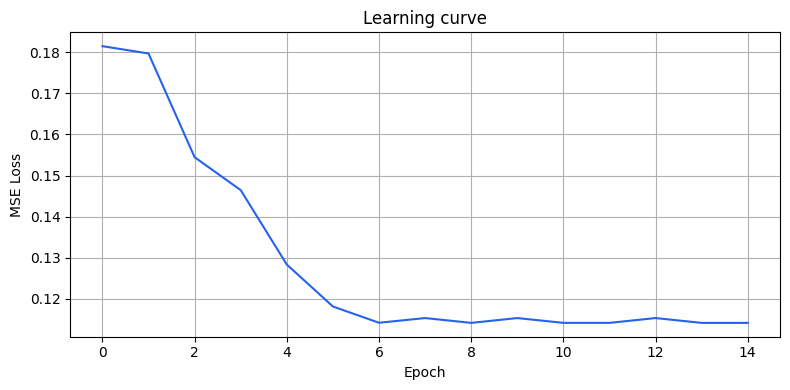

LIF weights saved to lif_weights.pt


In [87]:
# encoder and weights initialization
lif_weights = nn.Parameter(torch.ones(N_NEURONS, dtype=torch.float64) * 0.5)

print("Learning. LIF")
net_lif = LIFPopulation(
	weights=lif_weights,
	encoder=encoder,
	steps=STEPS,
	beta=BETA_LIF,
	threshold=THRESHOLD)

t0 = time.time()
losses = train_lif(
	encoder, lif_weights, train_dataldr,
	EPOCHS, LR_LIF, C_0, C_1, SIGMA, net_lif, STEPS)
print(f"LIF neuron training: {time.time()-t0:.1f}s")


print("Testing. LIF")

lif_accuracy = test_lif(
	encoder, lif_weights, test_dataldr,
	net_lif, C_0, C_1, STEPS, SIGMA)

print(f"\n  LIF. Testing accuracy: {lif_accuracy * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.plot(losses, color='#2563EB')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning curve')
plt.tight_layout()
plt.grid()
plt.show()

# Save trained LIF weights for reproducibility
torch.save({
    'weights': lif_weights.data,
    'accuracy': lif_accuracy,
}, 'lif_weights.pt')
print("LIF weights saved to lif_weights.pt")

# 6. Model Comparison

Both checkpoints are loaded from disk and evaluated on the same test set. This allows direct comparison of the proposed ExpNeuron model against the LIF baseline without re-running training.

In [88]:
# Load saved checkpoints
exp_ckpt = torch.load('exp_neuron_weights.pt',  weights_only=False)
lif_ckpt = torch.load('lif_weights.pt',  weights_only=False)

# Reconstruct ExpNeuron network from checkpoint
exp_weights_loaded = nn.Parameter(exp_ckpt['weights'])
net_exp_loaded = PopulationNet(
    weights=exp_weights_loaded, encoder=encoder, steps=STEPS,
    beta=BETA_EXP, threshold=THRESHOLD, membrane_zero=MEM_ZERO)
exp_acc = evaluate(
    encoder, exp_weights_loaded, test_dataldr,
    net_exp_loaded, C_0, C_1, STEPS, MEM_ZERO, THRESHOLD, BETA_EXP)

# Reconstruct LIF network from checkpoint
lif_weights_loaded = nn.Parameter(lif_ckpt['weights'])
net_lif_loaded = LIFPopulation(
    weights=lif_weights_loaded, encoder=encoder,
    steps=STEPS, beta=BETA_LIF, threshold=THRESHOLD)
lif_acc = test_lif(
    encoder, lif_weights_loaded, test_dataldr,
    net_lif_loaded, C_0, C_1, STEPS, SIGMA)

# Print comparison table
print(f"{'=' * 42}")
print(f"{'Model':<25} {'Accuracy':>10}")
print(f"{'-' * 42}")
print(f"{'ExpNeuron (proposed)':<25} {exp_acc * 100:>9.1f}%")
print(f"{'LIF (baseline)':<25} {lif_acc * 100:>9.1f}%")
print(f"{'=' * 42}")


Model                       Accuracy
------------------------------------------
ExpNeuron (proposed)           95.5%
LIF (baseline)                 93.5%


In [89]:
N_RUNS    = 10
BASE_SEED = 42

exp_w_mr = nn.Parameter(torch.load('exp_neuron_weights.pt', weights_only=False)['weights'])
lif_w_mr = nn.Parameter(torch.load('lif_weights.pt', weights_only=False)['weights'])

net_exp_mr = PopulationNet(weights=exp_w_mr, encoder=encoder, steps=STEPS,
                           beta=BETA_EXP, threshold=THRESHOLD, membrane_zero=MEM_ZERO)
net_lif_mr = LIFPopulation(weights=lif_w_mr, encoder=encoder,
                           steps=STEPS, beta=BETA_LIF, threshold=THRESHOLD)

# фиксированный набор λ и меток на все прогоны
torch.manual_seed(BASE_SEED)
_lam   = torch.ones(TEST_SAMPLES).uniform_(LAMBDA_MIN, LAMBDA_MAX)
_lbl   = ((torch.abs(_lam - LAMBDA) <= 5e-3) | (_lam > LAMBDA)).float()
_lam_i = torch.stack([encoder(l).squeeze(0) for l in _lam])

def _eval_pass(trains, net, is_exp):
    correct = none_cnt = 0
    for i in range(trains.shape[0]):
        out = net(trains[i].unsqueeze(0))
        out = out[0] if is_exp else out
        pred = decode_presence(out.squeeze(0))
        if pred is None:
            none_cnt += 1
        elif pred == int(_lbl[i].item()):
            correct += 1
    S = trains.shape[0]
    return correct / S, none_cnt / S

exp_acc_runs, lif_acc_runs, exp_none_runs, lif_none_runs = [], [], [], []
for r in range(N_RUNS):
    torch.manual_seed(BASE_SEED + 1 + r)
    trains = torch.stack([gen_spike_train(_lam_i[i], STEPS) for i in range(TEST_SAMPLES)])
    a_e, n_e = _eval_pass(trains, net_exp_mr, True)
    a_l, n_l = _eval_pass(trains, net_lif_mr, False)
    exp_acc_runs.append(a_e);  lif_acc_runs.append(a_l)
    exp_none_runs.append(n_e); lif_none_runs.append(n_l)

def _ms(a): return float(np.mean(a)), float(np.std(a))
ea, es  = _ms(exp_acc_runs);  la, ls  = _ms(lif_acc_runs)
en, ens = _ms(exp_none_runs); ln, lns = _ms(lif_none_runs)

print(f"Multi-run тест: {N_RUNS} прогонов x {TEST_SAMPLES} сэмплов")
print("=" * 52)
print(f"{'Model':<14}{'Accuracy (mean ± std)':>30}")
print("-" * 52)
print(f"{'ExpNeuron':<14}{ea*100:>18.1f}%  ± {es*100:>4.1f}%")
print(f"{'LIF':<14}{la*100:>18.1f}%  ± {ls*100:>4.1f}%")
print("=" * 52)
print(f"'никто не спайкнул':  ExpNeuron {en*100:.1f}% ± {ens*100:.1f}%   "
      f"LIF {ln*100:.1f}% ± {lns*100:.1f}%")

Multi-run тест: 10 прогонов x 200 сэмплов
Model                  Accuracy (mean ± std)
----------------------------------------------------
ExpNeuron                   91.6%  ±  1.6%
LIF                         89.2%  ±  0.8%
'никто не спайкнул':  ExpNeuron 0.3% ± 0.2%   LIF 0.1% ± 0.1%
